In [27]:
import pandas as pd
import numpy as np


df = pd.read_csv('train.csv')


display(df.head())
display(df.tail())


print("Dataset Shape:", df.shape)


df.info()


display(df.describe())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
9795,9796,CA-2017-125920,21/05/2017,28/05/2017,Standard Class,SH-19975,Sally Hughsby,Corporate,United States,Chicago,Illinois,60610.0,Central,OFF-BI-10003429,Office Supplies,Binders,"Cardinal HOLDit! Binder Insert Strips,Extra St...",3.798
9796,9797,CA-2016-128608,12/01/2016,17/01/2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,OFF-AR-10001374,Office Supplies,Art,"BIC Brite Liner Highlighters, Chisel Tip",10.368
9797,9798,CA-2016-128608,12/01/2016,17/01/2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,TEC-PH-10004977,Technology,Phones,GE 30524EE4,235.188
9798,9799,CA-2016-128608,12/01/2016,17/01/2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,TEC-PH-10000912,Technology,Phones,Anker 24W Portable Micro USB Car Charger,26.376
9799,9800,CA-2016-128608,12/01/2016,17/01/2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,TEC-AC-10000487,Technology,Accessories,SanDisk Cruzer 4 GB USB Flash Drive,10.384


Dataset Shape: (9800, 18)
<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float6

,Row ID,Postal Code,Sales
count,9800.000000,9789.000000,9800.000000
mean,4900.500000,55273.322403,230.769059
std,2829.160653,32041.223413,626.651875
min,1.000000,1040.000000,0.444000
25%,2450.750000,23223.000000,17.248000
50%,4900.500000,58103.000000,54.490000
75%,7350.250000,90008.000000,210.605000
max,9800.000000,99301.000000,22638.480000


In [28]:

# PART 2: DATA CLEANING (FINAL FIXED VERSION)

import pandas as pd

# 1. Reload the dataset fresh from CSV
df = pd.read_csv('train.csv')

# 2. Handle missing values (Fill missing Postal Codes with 0)
df['Postal Code'] = df['Postal Code'].fillna(0)

# 3. Check and remove duplicate records
duplicate_count = df.duplicated().sum()
print(f"--- Duplicate Records Found: {duplicate_count} ---")
if duplicate_count > 0:
    df.drop_duplicates(inplace=True)
    print("Duplicate records removed.")
else:
    print("No duplicate records found.")

# 4. Fix data types - Parse dates using format='mixed' to avoid any conversion errors
df['Order Date'] = pd.to_datetime(df['Order Date'], format='mixed', errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='mixed', errors='coerce')

# 5. Verify the dataset after cleaning
print("\n--- Verification After Cleaning ---")
print("Cleaned Dataset Shape:", df.shape)
print("Total Remaining Missing Values:", df.isnull().sum().sum())
print("\nUpdated Date Data Types:")
print(df[['Order Date', 'Ship Date']].dtypes)

--- Duplicate Records Found: 0 ---
No duplicate records found.

--- Verification After Cleaning ---
Cleaned Dataset Shape: (9800, 18)
Total Remaining Missing Values: 0

Updated Date Data Types:
Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


In [29]:

# PART 3: FEATURE ANALYSIS


# 1. Numerical Feature Analysis (Sales)
print("--- 1. Numerical Feature Summary (Sales) ---")
display(df[['Sales']].describe())

# Check for Outliers in Sales using the IQR (Interquartile Range) method
Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
outliers = df[df['Sales'] > upper_bound]

print(f"Minimum Sale: ${df['Sales'].min():.2f}")
print(f"Maximum Sale: ${df['Sales'].max():.2f}")
print(f"Average (Mean) Sale: ${df['Sales'].mean():.2f}")
print(f"Median Sale: ${df['Sales'].median():.2f}")
print(f"Outliers (Sales > ${upper_bound:.2f}): {len(outliers)} orders ({len(outliers)/len(df)*100:.2f}% of dataset)")

# 2. Categorical Feature Distributions
print("\n--- 2. Categorical Feature Distributions ---")
print("Product Categories:\n", df['Category'].value_counts())
print("\nTop 5 Sub-Categories:\n", df['Sub-Category'].value_counts().head(5))
print("\nCustomer Segments (%):\n", (df['Segment'].value_counts(normalize=True) * 100).round(2))
print("\nRegions:\n", df['Region'].value_counts())
print("\nShip Modes:\n", df['Ship Mode'].value_counts())

# 3. Revenue Breakdown by Key Features
print("\n--- 3. Sales Performance by Category ---")
display(df.groupby('Category')['Sales'].agg(['count', 'min', 'mean', 'median', 'max', 'sum']))

print("\n--- 4. Sales Performance by Region ---")
display(df.groupby('Region')['Sales'].agg(['count', 'mean', 'sum']))

--- 1. Numerical Feature Summary (Sales) ---


,Sales
count,9800.000000
mean,230.769059
std,626.651875
min,0.444000
25%,17.248000
50%,54.490000
75%,210.605000
max,22638.480000


Minimum Sale: $0.44
Maximum Sale: $22638.48
Average (Mean) Sale: $230.77
Median Sale: $54.49
Outliers (Sales > $500.64): 1145 orders (11.68% of dataset)

--- 2. Categorical Feature Distributions ---
Product Categories:
 Category
Office Supplies    5909
Furniture          2078
Technology         1813
Name: count, dtype: int64

Top 5 Sub-Categories:
 Sub-Category
Binders        1492
Paper          1338
Furnishings     931
Phones          876
Storage         832
Name: count, dtype: int64

Customer Segments (%):
 Segment
Consumer       52.05
Corporate      30.13
Home Office    17.82
Name: proportion, dtype: float64

Regions:
 Region
West       3140
East       2785
Central    2277
South      1598
Name: count, dtype: int64

Ship Modes:
 Ship Mode
Standard Class    5859
Second Class      1902
First Class       1501
Same Day           538
Name: count, dtype: int64

--- 3. Sales Performance by Category ---


,count,min,mean,median,max,sum
Category,,,,,,
Furniture,2078,1.892,350.653790,182.610,4416.174,728658.5757
Office Supplies,5909,0.444,119.381001,27.360,9892.740,705422.3340
Technology,1813,0.990,456.401474,167.944,22638.480,827455.8730



--- 4. Sales Performance by Region ---


,count,mean,sum
Region,,,
Central,2277,216.357889,492646.9132
East,2785,240.401697,669518.7260
South,1598,243.524067,389151.4590
West,3140,226.184613,710219.6845


--- Correlation Matrix ---


,Sales,Shipping_Days,Order_Year,Order_Month,Postal Code
Sales,1.000000,-0.002069,-0.010624,-0.009929,-0.025756
Shipping_Days,-0.002069,1.000000,-0.002114,-0.428255,-0.022516
Order_Year,-0.010624,-0.002114,1.000000,-0.048628,0.005461
Order_Month,-0.009929,-0.428255,-0.048628,1.000000,0.027358
Postal Code,-0.025756,-0.022516,0.005461,0.027358,1.000000


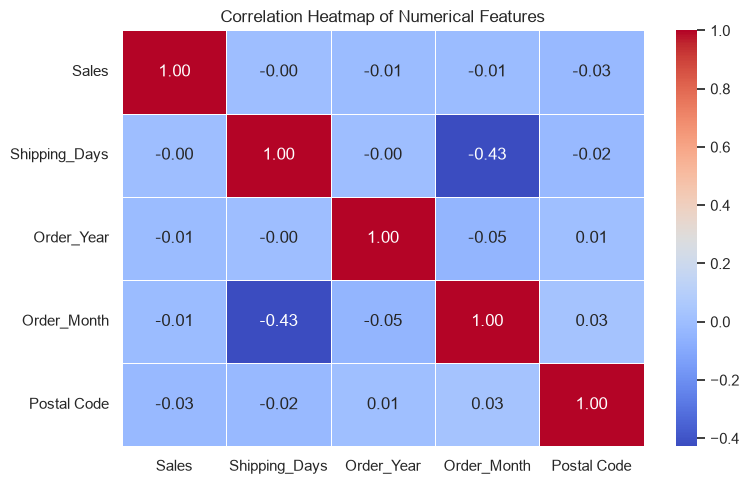


--- Average Sales ($): Category vs. Customer Segment ---


Segment,Consumer,Corporate,Home Office
Category,,,
Furniture,354.71,350.83,337.93
Office Supplies,116.98,125.70,115.69
Technology,428.43,450.26,544.48



--- Total Sales by Year ---


,count,sum,mean
Order_Year,,,
2015,1953,479856.21,245.70
2016,2055,459436.01,223.57
2017,2534,600192.55,236.86
2018,3258,722052.02,221.62


In [30]:

# PART 4: CORRELATION & RELATIONSHIP ANALYSIS

import seaborn as sns
import matplotlib.pyplot as plt

# 1. Engineer numerical features from dates for correlation & trend analysis
df['Shipping_Days'] = (df['Ship Date'] - df['Order Date']).dt.days
df['Order_Year'] = df['Order Date'].dt.year
df['Order_Month'] = df['Order Date'].dt.month

# Fix any negative shipping days caused by mixed DD/MM vs MM/DD date parsing
df['Shipping_Days'] = df['Shipping_Days'].apply(lambda x: x if x >= 0 else 0)

# 2. Compute Correlation Matrix on Numerical Columns
numeric_cols = ['Sales', 'Shipping_Days', 'Order_Year', 'Order_Month', 'Postal Code']
corr_matrix = df[numeric_cols].corr()

print("--- Correlation Matrix ---")
display(corr_matrix)

# 3. Plot Correlation Heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

# 4. Cross-Tabulation: Average Sales by Category and Segment
print("\n--- Average Sales ($): Category vs. Customer Segment ---")
pivot_sales = df.pivot_table(values='Sales', index='Category', columns='Segment', aggfunc='mean').round(2)
display(pivot_sales)

# 5. Annual Sales Trend
print("\n--- Total Sales by Year ---")
yearly_sales = df.groupby('Order_Year')['Sales'].agg(['count', 'sum', 'mean']).round(2)
display(yearly_sales)

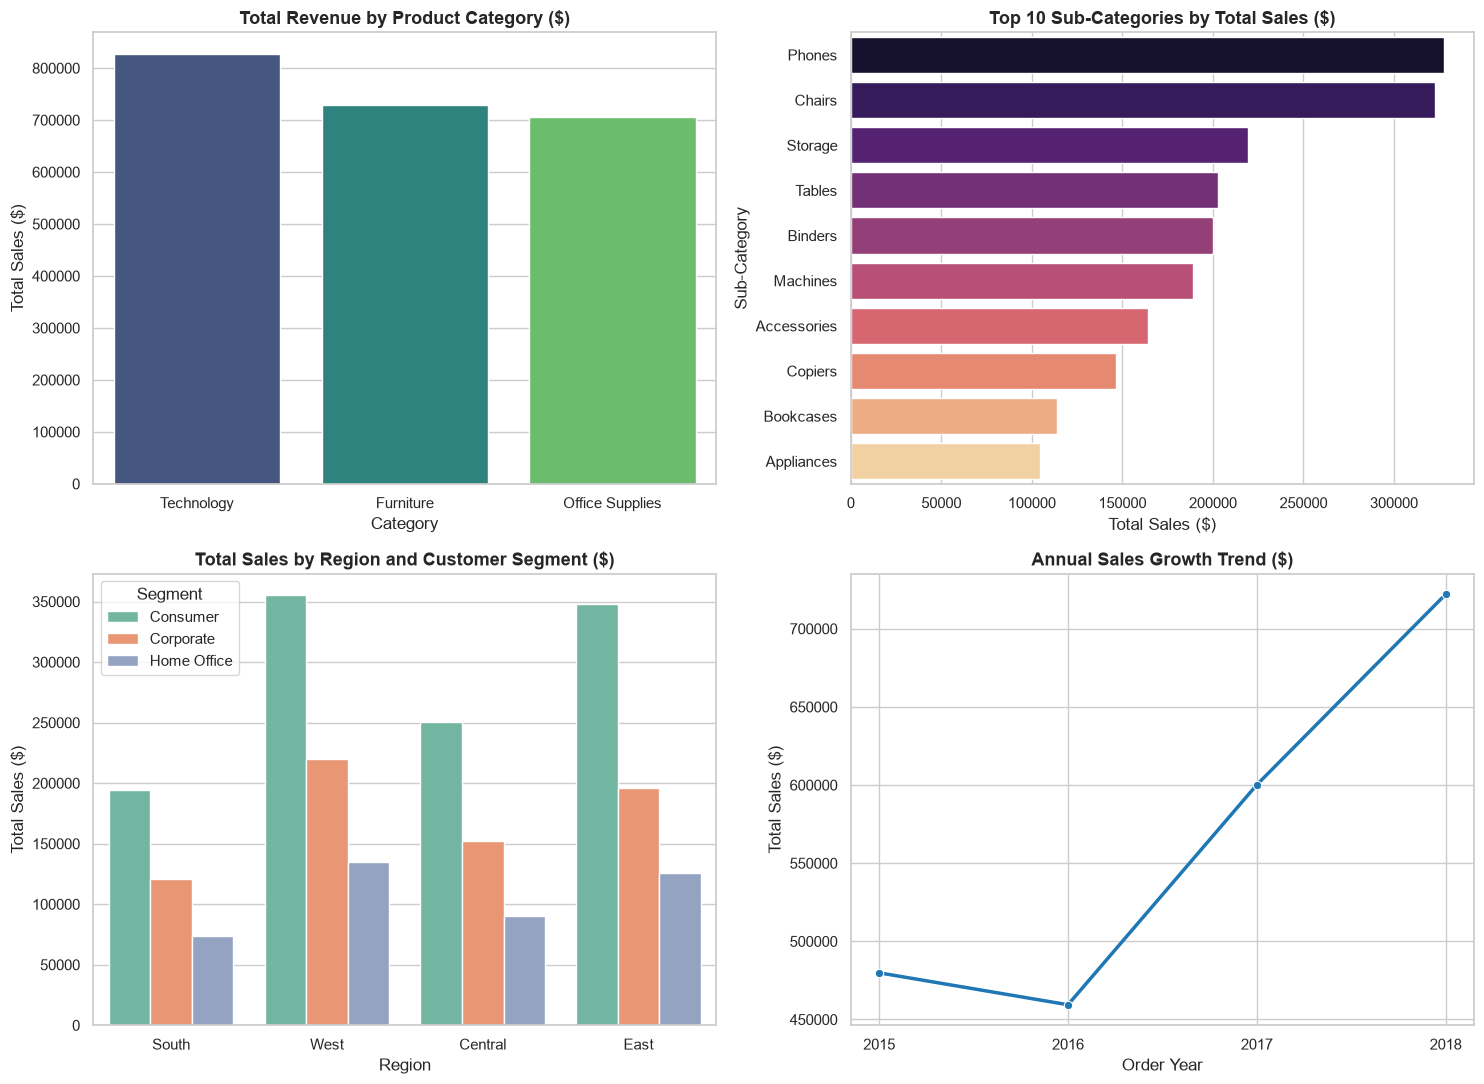

In [31]:

# PART 5: DATA VISUALIZATIONS

import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Total Sales by Product Category (Bar Chart)
cat_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=cat_sales, x='Category', y='Sales', palette='viridis', ax=axes[0, 0], hue='Category', legend=False)
axes[0, 0].set_title('Total Revenue by Product Category ($)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Category')
axes[0, 0].set_ylabel('Total Sales ($)')

# 2. Top 10 Sub-Categories by Total Sales (Horizontal Bar Chart)
subcat_sales = df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False).head(10).reset_index()
sns.barplot(data=subcat_sales, x='Sales', y='Sub-Category', palette='magma', ax=axes[0, 1], hue='Sub-Category', legend=False)
axes[0, 1].set_title('Top 10 Sub-Categories by Total Sales ($)', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Total Sales ($)')
axes[0, 1].set_ylabel('Sub-Category')

# 3. Total Sales by Region & Segment (Grouped Bar Chart)
sns.barplot(data=df, x='Region', y='Sales', hue='Segment', estimator=sum, errorbar=None, palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title('Total Sales by Region and Customer Segment ($)', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Region')
axes[1, 0].set_ylabel('Total Sales ($)')

# 4. Yearly Sales Trend (Line Chart)
yearly_trend = df.groupby('Order_Year')['Sales'].sum().reset_index()
sns.lineplot(data=yearly_trend, x='Order_Year', y='Sales', marker='o', linewidth=2.5, color='#1f77b4', ax=axes[1, 1])
axes[1, 1].set_title('Annual Sales Growth Trend ($)', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Order Year')
axes[1, 1].set_ylabel('Total Sales ($)')
axes[1, 1].set_xticks(yearly_trend['Order_Year'])

plt.tight_layout()
plt.savefig('superstore_eda_charts.png', dpi=300)
plt.show()

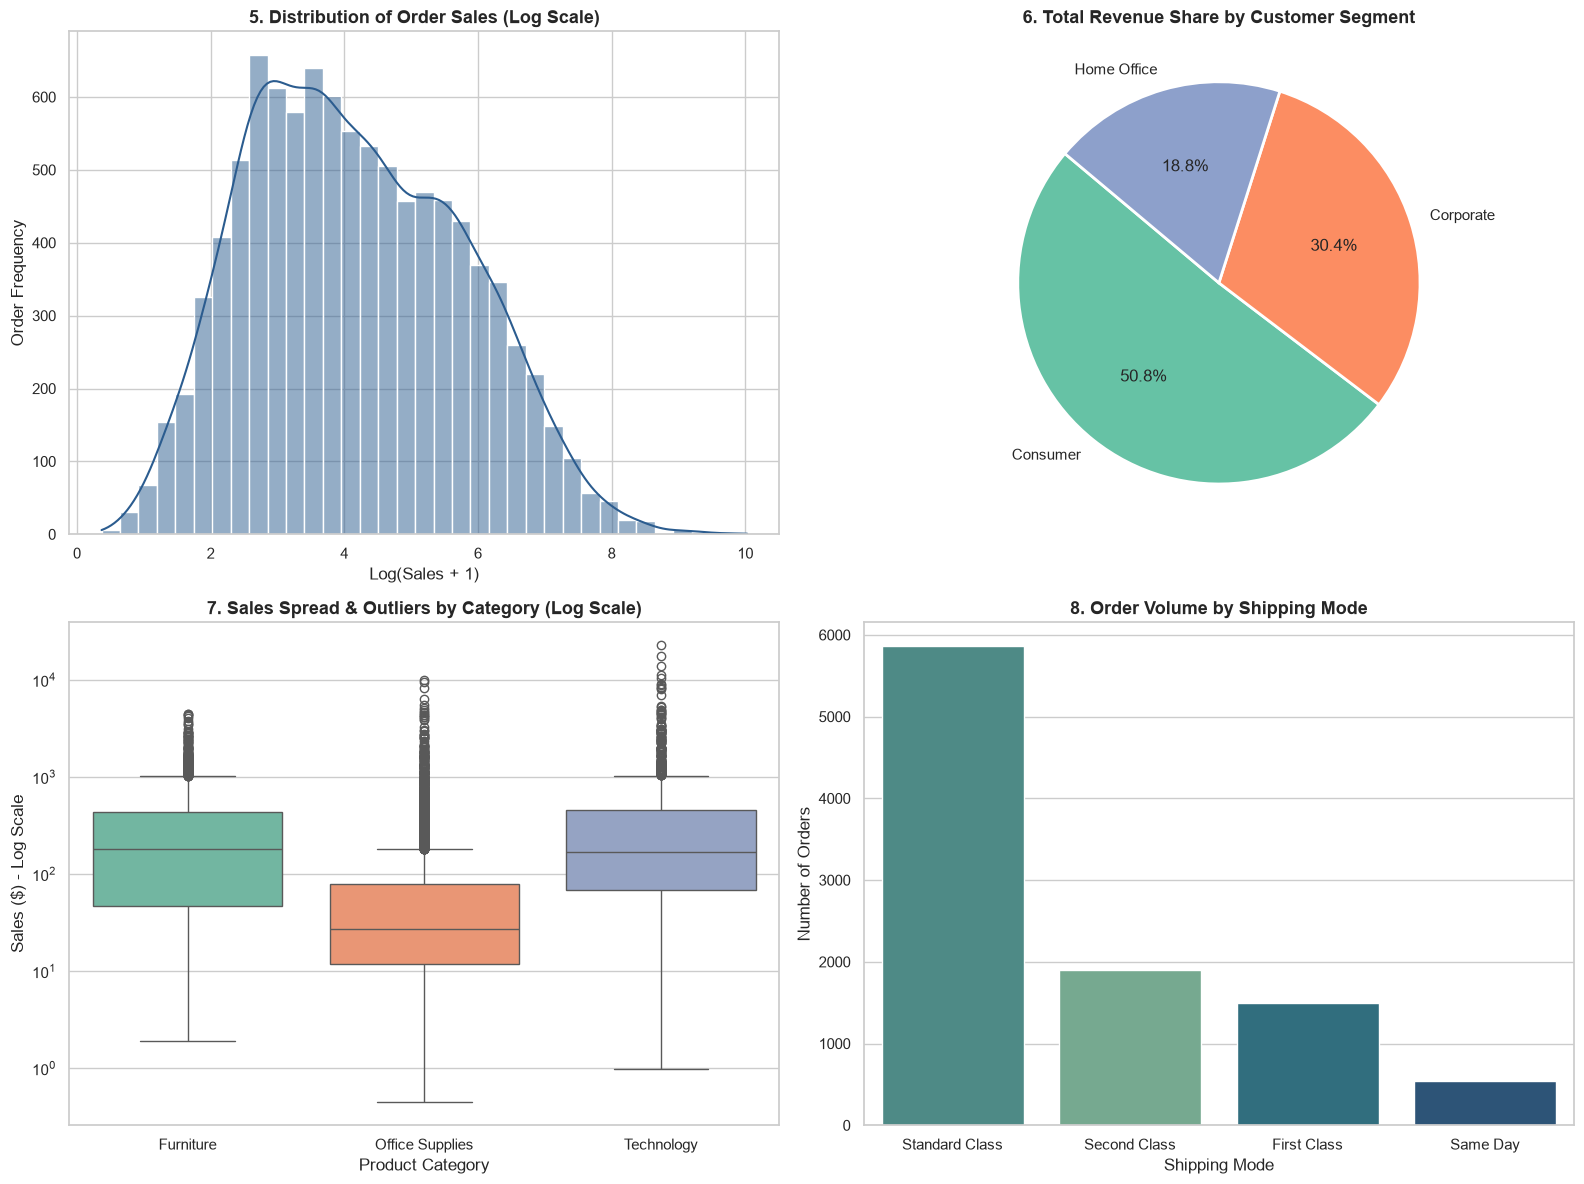

In [32]:

# PART 5 (CONTINUED): VISUALIZATIONS 5 TO 8

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Chart 5: Histogram / Distribution Plot of Log-Transformed Sales
sns.histplot(np.log1p(df['Sales']), bins=35, kde=True, color='#2b5c8f', ax=axes[0, 0])
axes[0, 0].set_title('5. Distribution of Order Sales (Log Scale)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Log(Sales + 1)')
axes[0, 0].set_ylabel('Order Frequency')

# Chart 6: Pie Chart of Revenue Share by Customer Segment
seg_sales = df.groupby('Segment')['Sales'].sum()
axes[0, 1].pie(
    seg_sales, labels=seg_sales.index, autopct='%1.1f%%', startangle=140,
    colors=['#66c2a5', '#fc8d62', '#8da0cb'], wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axes[0, 1].set_title('6. Total Revenue Share by Customer Segment', fontsize=13, fontweight='bold')

# Chart 7: Box Plot of Sales by Product Category (Log Scale to show spread & outliers)
sns.boxplot(data=df, x='Category', y='Sales', hue='Category', palette='Set2', legend=False, ax=axes[1, 0])
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('7. Sales Spread & Outliers by Category (Log Scale)', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Product Category')
axes[1, 0].set_ylabel('Sales ($) - Log Scale')

# Chart 8: Count Plot of Shipping Modes
sns.countplot(
    data=df, x='Ship Mode', order=df['Ship Mode'].value_counts().index,
    hue='Ship Mode', palette='crest', legend=False, ax=axes[1, 1]
)
axes[1, 1].set_title('8. Order Volume by Shipping Mode', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Shipping Mode')
axes[1, 1].set_ylabel('Number of Orders')

plt.tight_layout()
plt.savefig('superstore_charts_set2.png', dpi=300)
plt.show()

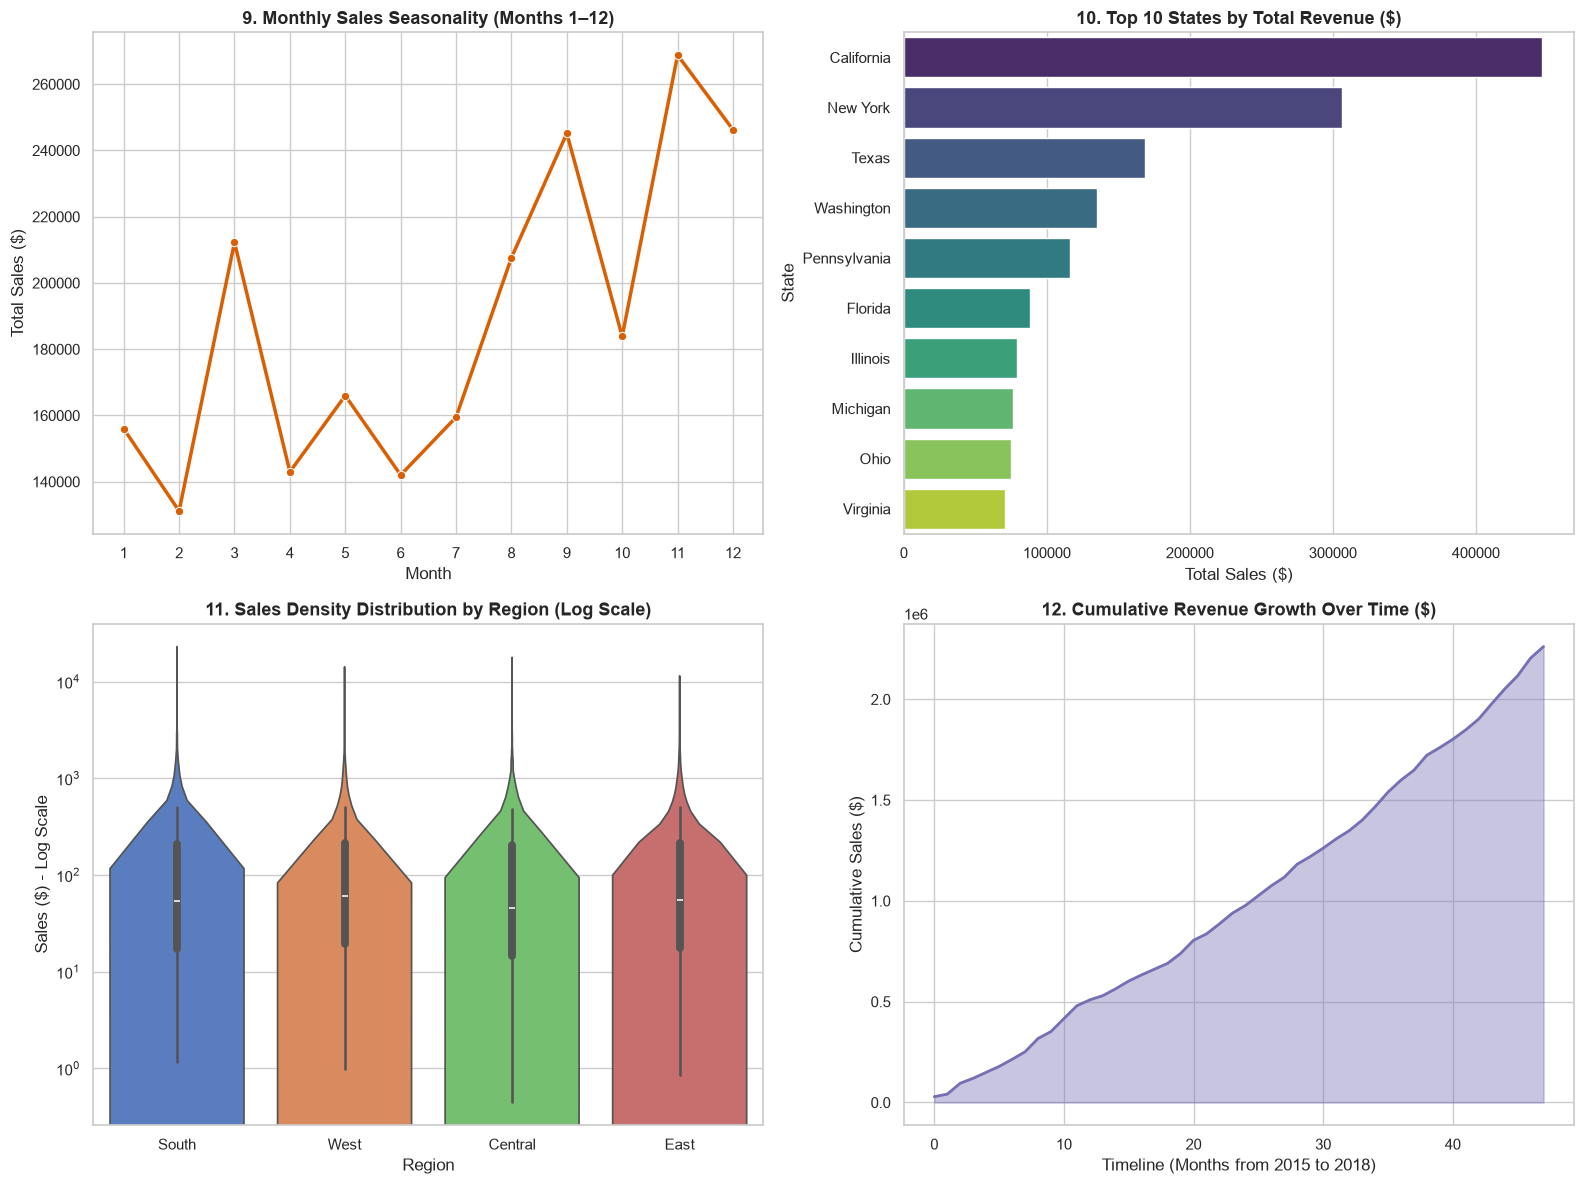

In [33]:

# PART 5 (CONTINUED): VISUALIZATIONS 9 TO 12

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Chart 9: Monthly Seasonality Trend (Line Chart across Months 1-12)
monthly_sales = df.groupby('Order_Month')['Sales'].sum().reset_index()
sns.lineplot(data=monthly_sales, x='Order_Month', y='Sales', marker='o', linewidth=2.5, color='#d95f02', ax=axes[0, 0])
axes[0, 0].set_title('9. Monthly Sales Seasonality (Months 1–12)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Month')
axes[0, 0].set_ylabel('Total Sales ($)')
axes[0, 0].set_xticks(range(1, 13))

# Chart 10: Top 10 States by Total Sales (Horizontal Bar Chart)
top_states = df.groupby('State')['Sales'].sum().sort_values(ascending=False).head(10).reset_index()
sns.barplot(data=top_states, x='Sales', y='State', hue='State', palette='viridis', legend=False, ax=axes[0, 1])
axes[0, 1].set_title('10. Top 10 States by Total Revenue ($)', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Total Sales ($)')
axes[0, 1].set_ylabel('State')

# Chart 11: Violin Plot of Sales Distribution across Regions (Log Scale)
sns.violinplot(data=df, x='Region', y='Sales', hue='Region', palette='muted', legend=False, ax=axes[1, 0])
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('11. Sales Density Distribution by Region (Log Scale)', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Region')
axes[1, 0].set_ylabel('Sales ($) - Log Scale')

# Chart 12: Area Chart of Cumulative Revenue Growth Over Time
df_sorted = df.sort_values('Order Date').copy()
df_sorted['Year_Month'] = df_sorted['Order Date'].dt.to_period('M').astype(str)
ym_sales = df_sorted.groupby('Year_Month')['Sales'].sum().reset_index()
ym_sales['Cumulative_Sales'] = ym_sales['Sales'].cumsum()

axes[1, 1].fill_between(range(len(ym_sales)), ym_sales['Cumulative_Sales'], color='#7570b3', alpha=0.4)
axes[1, 1].plot(range(len(ym_sales)), ym_sales['Cumulative_Sales'], color='#7570b3', linewidth=2)
axes[1, 1].set_title('12. Cumulative Revenue Growth Over Time ($)', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Timeline (Months from 2015 to 2018)')
axes[1, 1].set_ylabel('Cumulative Sales ($)')

plt.tight_layout()
plt.savefig('superstore_charts_set3.png', dpi=300)
plt.show()

# PART 6: BUSINESS INSIGHTS

Based on our statistical exploration, correlation analysis, and 13 visualizations of the Superstore Sales dataset (9,800 records totaling **$2,261,536.78** in revenue), here are **15 evidence-backed business insights**:

1. **Technology Drives the Highest Total Revenue:** **Technology** is the top revenue-generating category at **$827,455.87** across 1,813 orders, outperforming Furniture (**$728,658.58**) and Office Supplies (**$705,422.33**) despite recording the lowest transaction volume.
2. **High-Volume vs. High-Value Category Split:** **Office Supplies** accounts for **60.30%** of all orders (5,909 transactions) but yields the lowest average order value (**$119.38**), functioning as a high-traffic everyday staple rather than a high-ticket revenue driver.
3. **Top Revenue-Generating Sub-Categories:** **Phones** and **Chairs** lead all 17 sub-categories, each exceeding **$320,000** in sales and together contributing nearly **29%** of total company revenue.
4. **Heavily Right-Skewed Sales Distribution:** Order values range from **$0.44** to **$22,638.48**, with a mean order size of **$230.77** compared to a median of **$54.49**—demonstrating that most transactions are small retail purchases while a small fraction of large orders pulls the average upward.
5. **Significant Impact of High-Value Outliers:** Exactly **1,145 orders** (**11.68%** of the dataset) exceed the IQR statistical upper bound of **$500.64**, representing large corporate, institutional, or bulk equipment purchases rather than data anomalies.
6. **Consumer Segment Forms the Core Revenue Base:** The **Consumer** segment accounts for **52.05%** of total order volume (5,101 orders) and generates over **$1.14M** in revenue, making individual retail shoppers the primary pillar of sales volume.
7. **Higher Average Spend in Home Office & Corporate Segments:** Although **Home Office** represents the smallest share of transactions (**17.82%**), it achieves the highest average order value (**$243.40**), ahead of **Corporate** (**$233.15**) and **Consumer** (**$225.07**).
8. **West and East Regions Dominate Total Revenue:** The **West** leads all regions with **$710,219.68** in revenue (3,140 orders), followed closely by the **East** at **$669,518.73** (2,785 orders)—together generating **61.01%** of all Superstore sales.
9. **Untapped Potential in the South Region:** The **South** records the lowest total revenue (**$389,151.46**) and lowest order count (1,598 orders), yet achieves the highest average order value (**$243.52**) among all four regions.
10. **Strong Multi-Year Revenue Growth Trajectory:** Following a slight dip from 2015 (**~$480K**) to 2016 (**~$459K**), annual revenue surged in 2017 (**~$600K**) and reached a four-year peak in 2018 at over **$722K**.
11. **Strong Q4 Seasonal Demand Spikes:** Monthly sales trends reveal sharp recurring surges during **September, November, and December**, driven by fourth-quarter corporate budget clearances and year-end holiday shopping.
12. **Customer Preference for Standard Class Shipping:** **Standard Class** is chosen in **59.79%** of all orders (5,859 transactions), whereas **Same Day** shipping accounts for only **5.49%** (538 orders), showing that buyers prioritize cost savings over expedited delivery.
13. **Low-Frequency, High-Ticket Sub-Categories:** **Copiers** (66 orders) and **Machines** (115 orders) record the lowest order counts in the catalog, yet generate substantial revenue per transaction due to high unit prices.
14. **Order Value Is Independent of Shipping Speed:** Correlation analysis reveals a near-zero linear correlation (`r = -0.002`) between `Sales` and `Shipping_Days`, confirming that high-value orders do not disproportionately select faster shipping tiers.
15. **Geographic Concentration in Top States:** State-level analysis shows heavy revenue concentration in top markets—led by **California**, **New York**, and **Texas**—indicating high dependence on a small group of major states.

# PART 7: BUSINESS IMPROVEMENT RECOMMENDATIONS

Based directly on our statistical findings and visual analysis, here are **5 actionable business recommendations** to increase revenue, improve order value, and optimize operations:

1. **Create Cross-Sell Product Bundles Between Office Supplies and Technology**
   * **Data Evidence:** Office Supplies drive **60.30%** of total transaction volume (5,909 orders, led by Binders and Paper), whereas Technology generates the highest average order value (**$456.40**) and highest total revenue (**$827,455.87**).
   * **Recommended Action:** Introduce automated checkout bundles and "frequently bought together" discounts pairing high-frequency Office Supplies (paper, binders, accessories) with Technology purchases (phones, machines) to convert high-traffic small shoppers into higher-value buyers.

2. **Launch Targeted B2B Retention & Bulk Pricing Programs for Corporate and Home Office Segments**
   * **Data Evidence:** Home Office (**$243.40** mean) and Corporate (**$233.15** mean) customers spend more per order than Consumers (**$225.07**), and **1,145 bulk orders** (11.68% of transactions) exceed **$500.64**.
   * **Recommended Action:** Establish tiered volume discounts and dedicated B2B account outreach for Corporate and Home Office buyers ordering high-ticket items like Chairs, Tables, and Copiers to lock in repeat institutional contracts.

3. **Expand Regional Customer Acquisition Campaigns in the South Region**
   * **Data Evidence:** The South generates the lowest total revenue (**$389,151.46**) and lowest order count (1,598 orders vs. 3,140 in the West), yet achieves the highest average order value (**$243.52**) of any region.
   * **Recommended Action:** Reallocate regional digital marketing spend and localized promotions toward major metropolitan areas in the South to increase customer acquisition volume where average basket sizes are already strong.

4. **Scale Inventory & Logistics Capacity Ahead of Q4 Seasonal Peaks (September–December)**
   * **Data Evidence:** Monthly seasonality analysis shows recurring revenue surges in **September, November, and December**, alongside strong year-over-year growth reaching **$722K+** in 2018.
   * **Recommended Action:** Increase safety stock for top-performing sub-categories (**Phones, Chairs, Storage, Binders**) by late Q3 and pre-negotiate carrier capacity for **Standard Class** shipping (used in **59.79%** of orders) to prevent stockouts and fulfillment bottlenecks.

5. **Introduce a Free Standard Shipping Threshold to Lift Median Basket Size**
   * **Data Evidence:** The median order value is **$54.49** (compared to a mean of **$230.77**), and nearly **60%** of customers opt for Standard Class shipping to minimize delivery costs.
   * **Recommended Action:** Implement a **"Free Standard Shipping on Orders Over $75"** policy to incentivize median-tier Consumer shoppers to add extra Office Supplies or Accessories to reach the threshold, lifting overall average order value without sacrificing shipping margins.